In [1]:
%% MIT 18.03 Lecture 37: Vector Fields, Nullclines & Jacobian Linearization
% Description: Analyzes the Deer-Wolf Nonlinear Predator-Prey System via Control System Toolbox:
%              x' = (3 - x - y)*x,  y' = (1 - y + x)*y
%              1) Evaluates Jacobian matrices J(a,b) at all 4 equilibria: (0,0), (3,0), (0,1), (1,2).
%              2) Constructs local LTI State-Space models via 'ss' and extracts poles/damping.
%              3) Plots global nonlinear phase portrait, nullclines, and basin of attraction.
%              4) Compares local linearized 'initial' response vs. exact nonlinear 'ode45' near (1,2).
%
% % Required Toolboxes:
% %   - Control System Toolbox (ss, initial, pole, damp).
%
% % MBD Concept Mapping: Demonstrates Trim / Equilibrium finding and Jacobian Linearization
% %                      du/dt = J(x_e, y_e)*u used in Simulink Model Linearizer and EKF.


clear; clc; close all;


%% =========================================================================
%% Part 1: Nonlinear System Definition & Jacobian at All 4 Equilibria
%% =========================================================================
% Nonlinear vector field F(x,y) = [f(x,y); g(x,y)]
f_nl = @(x, y) (3 - x - y) .* x;
g_nl = @(x, y) (1 - y + x) .* y;
ode_nl = @(t, U) [f_nl(U(1), U(2)); g_nl(U(1), U(2))];


% Analytical Jacobian Matrix J(x,y) from Lecture Section [4]:
% J(x,y) = [ 3 - 2x - y,     -x      ;
%                y     , 1 + x - 2y  ]
J_func = @(x, y) [3 - 2*x - y,      -x     ;
                       y     ,  1 + x - 2*y];


% The 4 Equilibrium Points derived in Section [3]
equilibria = [0, 0;
              3, 0;
              0, 1;
              1, 2];
eq_names = {'Origin (Extinction)', 'Deer-Only Boundary', 'Wolf-Only Boundary', 'Coexistence Attractor'};


fprintf('=== MIT 18.03 Lecture 37 Jacobian Linearization Diagnostics ===\n');

=== MIT 18.03 Lecture 37 Jacobian Linearization Diagnostics ===

In [2]:
for k = 1:size(equilibria, 1)
    xe = equilibria(k, 1);
    ye = equilibria(k, 2);
    J_val = J_func(xe, ye);
    sys_lin_k = ss(J_val, zeros(2,1), eye(2), zeros(2,1));
    p_k = pole(sys_lin_k);

    % Classify local linear portrait
    if real(p_k(1)) * real(p_k(2)) < -1e-9
        type_str = 'Saddle Point (Unstable)';
    elseif abs(imag(p_k(1))) > 1e-6
        if real(p_k(1)) < 0
            type_str = 'Stable Spiral Sink (CCW)';
        else
            type_str = 'Unstable Spiral Source';
        end
    else
        if real(p_k(1)) > 0
            type_str = 'Unstable Node (Source)';
        else
            type_str = 'Stable Node (Sink)';
        end
    end

    fprintf('%d) Equilibrium (%d, %d) - %s:\n', k, xe, ye, eq_names{k});
    fprintf('   Jacobian J(%d,%d) = [ %+2d, %+2d ; %+2d, %+2d ]\n', ...
            xe, ye, J_val(1,1), J_val(1,2), J_val(2,1), J_val(2,2));
    fprintf('   Eigenvalues      = %+.4f %+.4fi,  %+.4f %+.4fi  -->  %s\n\n', ...
            real(p_k(1)), imag(p_k(1)), real(p_k(2)), imag(p_k(2)), type_str);
end

1) Equilibrium (0, 0) - Origin (Extinction):
   Jacobian J(0,0) = [ +3, +0 ; +0, +1 ]
   Eigenvalues      = +1.0000 +0.0000i,  +3.0000 +0.0000i  -->  Unstable Node (Source)
2) Equilibrium (3, 0) - Deer-Only Boundary:
   Jacobian J(3,0) = [ -3, -3 ; +0, +4 ]
   Eigenvalues      = -3.0000 +0.0000i,  +4.0000 +0.0000i  -->  Saddle Point (Unstable)
3) Equilibrium (0, 1) - Wolf-Only Boundary:
   Jacobian J(0,1) = [ +2, +0 ; +1, -1 ]
   Eigenvalues      = -1.0000 +0.0000i,  +2.0000 +0.0000i  -->  Saddle Point (Unstable)
4) Equilibrium (1, 2) - Coexistence Attractor:
   Jacobian J(1,2) = [ -1, -1 ; +2, -2 ]
   Eigenvalues      = -1.5000 +1.3229i,  -1.5000 -1.3229i  -->  Stable Spiral Sink (CCW)

In [3]:


% Detailed period calculation at Coexistence Equilibrium P = (1, 2)
J_coexist = J_func(1, 2); % [-1, -1; 2, -2]
sys_coexist = ss(J_coexist, zeros(2,1), eye(2), zeros(2,1));
wd_coexist = sqrt(7) / 2;
T_period = 2 * pi / wd_coexist;
fprintf('Coexistence Attractor (1,2) Spiral Period: 2*pi / (sqrt(7)/2) = %.4f years (~4.75)\n', T_period);

Coexistence Attractor (1,2) Spiral Period: 2*pi / (sqrt(7)/2) = 4.7496 years (~4.75)

In [4]:
fprintf('===============================================================\n');


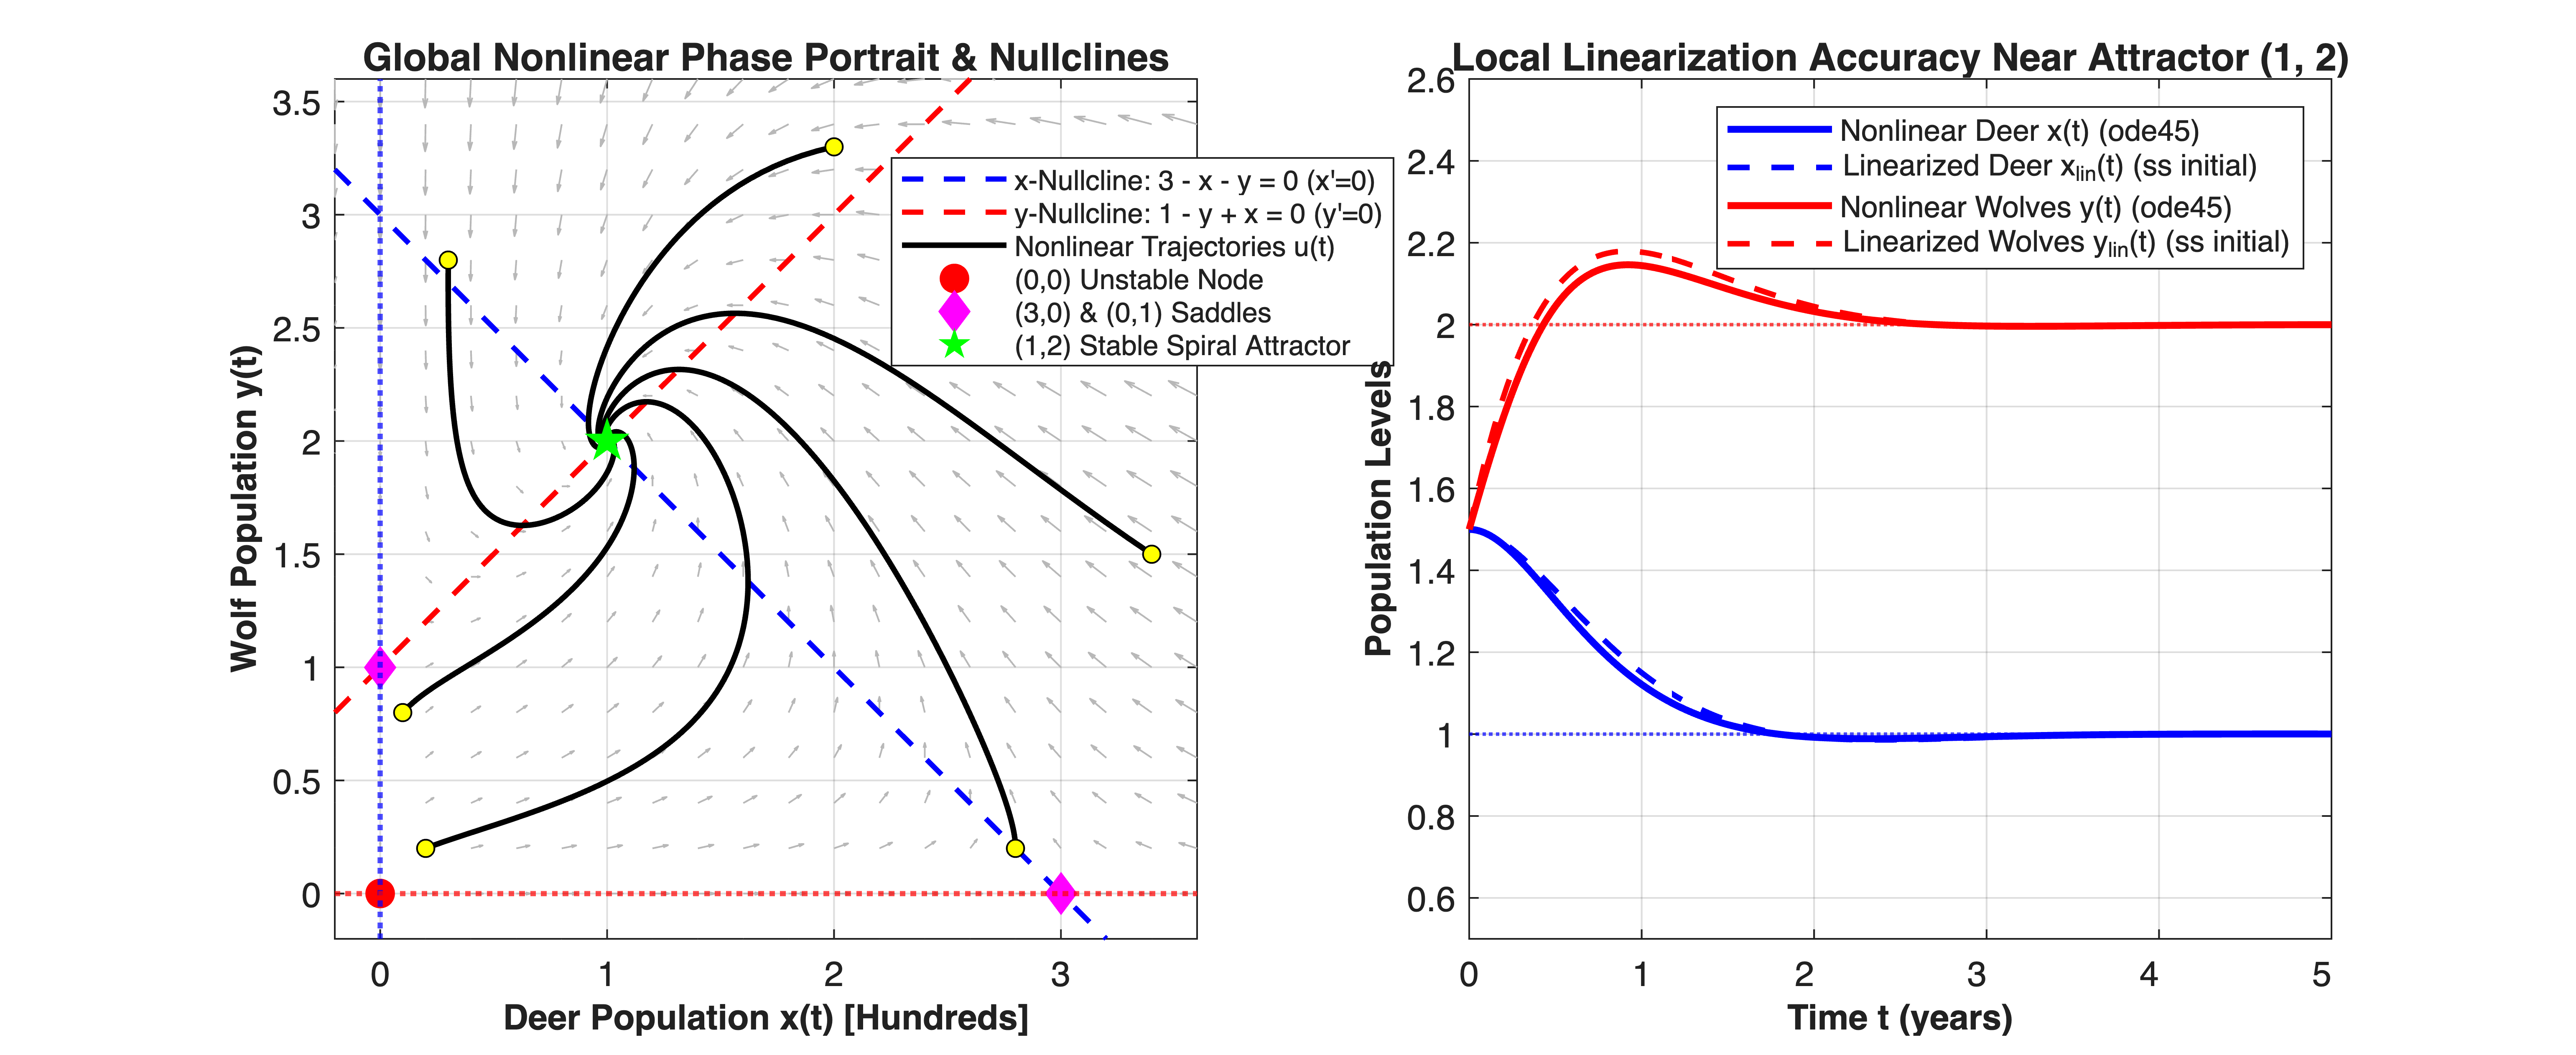

In [5]:


%% =========================================================================
%% Part 2: Global Nonlinear Phase Portrait & Local Linearization Comparison
%% =========================================================================
figure('Color', [1 1 1], 'Position', [70, 70, 1220, 500]);


% Subplot 1: Global Phase Plane, Nullclines, and Equilibria
subplot(1, 2, 1);
hold on; grid on; box on;


[Xg, Yg] = meshgrid(linspace(-0.2, 3.6, 20), linspace(-0.2, 3.6, 20));
Ug = f_nl(Xg, Yg);
Vg = g_nl(Xg, Yg);
% Normalize vector lengths slightly for clean direction visualization
mag_g = hypot(Ug, Vg); mag_g(mag_g == 0) = 1;
quiver(Xg, Yg, Ug./(mag_g.^0.6), Vg./(mag_g.^0.6), 0.6, 'Color', [0.72 0.72 0.72], ...
       'HandleVisibility', 'off');


% Plot Nullclines (Section [3])
x_line = linspace(-0.2, 3.6, 200);
plot(x_line, 3 - x_line, 'b--', 'LineWidth', 1.5, 'DisplayName', 'x-Nullcline: 3 - x - y = 0 (x''=0)');
plot(x_line, 1 + x_line, 'r--', 'LineWidth', 1.5, 'DisplayName', 'y-Nullcline: 1 - y + x = 0 (y''=0)');
xline(0, 'b:', 'LineWidth', 1.5, 'HandleVisibility', 'off');
yline(0, 'r:', 'LineWidth', 1.5, 'HandleVisibility', 'off');


% Simulate nonlinear trajectories from various initial populations in Quadrant I
ic_list = [0.2, 0.2;  2.8, 0.2;  3.4, 1.5;  2.0, 3.3;  0.3, 2.8;  0.1, 0.8]';
t_sim = linspace(0, 10, 600);
opts = odeset('RelTol', 1e-8, 'AbsTol', 1e-10);
for k = 1:size(ic_list, 2)
    [~, U_traj] = ode45(ode_nl, t_sim, ic_list(:, k), opts);
    plot(U_traj(:, 1), U_traj(:, 2), 'k-', 'LineWidth', 1.6, 'HandleVisibility', 'off');
    plot(ic_list(1, k), ic_list(2, k), 'ko', 'MarkerFaceColor', 'y', 'MarkerSize', 5, 'HandleVisibility', 'off');
end
plot(NaN, NaN, 'k-', 'LineWidth', 1.6, 'DisplayName', 'Nonlinear Trajectories u(t)');


% Mark the 4 Equilibria
plot(0, 0, 'ro', 'MarkerFaceColor', 'r', 'MarkerSize', 8, 'DisplayName', '(0,0) Unstable Node');
plot([3, 0], [0, 1], 'md', 'MarkerFaceColor', 'm', 'MarkerSize', 8, 'DisplayName', '(3,0) & (0,1) Saddles');
plot(1, 2, 'gp', 'MarkerFaceColor', 'g', 'MarkerSize', 12, 'DisplayName', '(1,2) Stable Spiral Attractor');


xlabel('Deer Population x(t) [Hundreds]', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('Wolf Population y(t)', 'FontSize', 10, 'FontWeight', 'bold');
title('Global Nonlinear Phase Portrait & Nullclines', 'FontSize', 11, 'FontWeight', 'bold');
legend('Location', 'northeast', 'FontSize', 8);
xlim([-0.2, 3.6]); ylim([-0.2, 3.6]);


% Subplot 2: Time-Domain Comparison Near (1,2): Linearized 'initial' vs. Nonlinear 'ode45'
subplot(1, 2, 2);
hold on; grid on; box on;


% Perturbed initial state near (1, 2): start at (x0, y0) = (1.5, 1.5) -> du0 = [+0.5; -0.5]
u_eq = [1.0; 2.0];
du0  = [0.5; -0.5];
u0_pert = u_eq + du0;


t_comp = linspace(0, 5.0, 500);
% 1. Exact Nonlinear Solution via ode45
[~, U_nl_comp] = ode45(ode_nl, t_comp, u0_pert, opts);


% 2. Linearized State-Space Approximation via Control System Toolbox 'initial'
% u_lin(t) = [1; 2] + du(t), where du' = J(1,2) * du
[du_lin, ~] = initial(sys_coexist, du0, t_comp);
U_lin_comp  = u_eq.' + du_lin;


plot(t_comp, U_nl_comp(:, 1), 'b-',  'LineWidth', 2.0, 'DisplayName', 'Nonlinear Deer x(t) (ode45)');
plot(t_comp, U_lin_comp(:, 1), 'b--', 'LineWidth', 1.6, 'DisplayName', 'Linearized Deer x_{lin}(t) (ss initial)');
plot(t_comp, U_nl_comp(:, 2), 'r-',  'LineWidth', 2.0, 'DisplayName', 'Nonlinear Wolves y(t) (ode45)');
plot(t_comp, U_lin_comp(:, 2), 'r--', 'LineWidth', 1.6, 'DisplayName', 'Linearized Wolves y_{lin}(t) (ss initial)');


yline(1.0, 'b:', 'LineWidth', 1.0, 'HandleVisibility', 'off');
yline(2.0, 'r:', 'LineWidth', 1.0, 'HandleVisibility', 'off');


xlabel('Time t (years)', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('Population Levels', 'FontSize', 10, 'FontWeight', 'bold');
title('Local Linearization Accuracy Near Attractor (1, 2)', 'FontSize', 11, 'FontWeight', 'bold');
legend('Location', 'northeast', 'FontSize', 8.5);
xlim([0, 5.0]); ylim([0.5, 2.6]);